In [1]:
!pip install boto3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 40.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [boto3]


In [2]:
import boto3, cv2, numpy as np, os
from dotenv import load_dotenv
from PIL import Image
from google.colab.patches import cv2_imshow

In [3]:
%%writefile .env
aws_bucket=amznbckt-izv
aws_region=us-east-1
aws_access_key_id=ASI...36J
aws_secret_access_key=PJQ...2XH
aws_session_token=IQoJ...sk9

Writing .env


In [27]:
load_dotenv(override=True)

aws_access_key_id = os.environ.get('aws_access_key_id')
aws_secret_access_key = os.environ.get('aws_secret_access_key')
aws_session_token = os.environ.get('aws_session_token')
aws_bucket = os.environ.get('aws_bucket')
aws_region = os.environ.get('aws_region')

In [28]:
session = boto3.Session(
        aws_access_key_id = aws_access_key_id,
        aws_secret_access_key = aws_secret_access_key,
        aws_session_token = aws_session_token,
        region_name = aws_region)
s3 = session.resource('s3')
rekognition = session.client('rekognition')

In [29]:
file = 'faces.jpg'
key = 'faces.jpg'
try:
  s3.Object(aws_bucket, key).upload_file(file)
except Exception as e:
  print(e)

In [30]:
try:
  response = rekognition.detect_faces(Image={'S3Object': {'Bucket': aws_bucket, 'Name': key}}, Attributes=['ALL'])
except Exception as e:
  print(e)

In [31]:
img = Image.open(file)
#img_cv2 = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2RGBA)
img_cv2 = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGRA)

height, width, _ = img_cv2.shape

for faceDetail in response['FaceDetails']:
  box = faceDetail['BoundingBox']
  x = int(width * box['Left'])
  y = int(height * box['Top'])
  w = int(width * box['Width'])
  h = int(height * box['Height'])
  roi = img_cv2[y:y+h, x:x+w]
  roi = cv2.GaussianBlur(roi, (83, 83), 30)
  img_cv2[y:y+roi.shape[0], x:x+roi.shape[1]] = roi
cv2.imwrite('faces_blur.jpg', img_cv2)

True

# Ejercicios

1. Desarrolla un script que detecte personas en una fotografía y genere un informe con los resultados que puedas extraer. En este caso, se obtiene más información que en la práctica anterior.

2. Modifica el código proporcionado para que, utilizando Amazon Rekognition y OpenCV, se aplique un efecto de desenfoque (blur) a toda la imagen, manteniendo los rostros detectados nítidos y sin desenfocar. La idea es utilizar cv2.GaussianBlur() para desenfocar la imagen completa y, después, copiar sobre ella las regiones faciales de la imagen original utilizando las coordenadas que devuelve Rekognition.

3. Modifica el código proporcionado para que, utilizando Amazon Rekognition y OpenCV, se detecten y recorten todos los rostros de una fotografía y se genere un collage que contenga únicamente los rostros detectados.
Requisitos:
    Detectar los rostros de la imagen mediante Amazon Rekognition.
    Recortar cada rostro utilizando las coordenadas devueltas por el servicio.
    Redimensionar los recortes para que tengan unas dimensiones uniformes.
    Organizar los rostros en una cuadrícula y generar una única imagen con todos ellos.
    Mostrar y guardar el collage resultante.
Ampliación: modifica el número de filas y columnas del collage y comprueba el resultado con fotografías que contengan diferentes cantidades de rostros.

In [32]:
# ejercicio 1
caras = response['FaceDetails']
print("Personas detectadas:", len(caras))
print()

for i, cara in enumerate(caras, 1):
    edad_min = cara['AgeRange']['Low']
    edad_max = cara['AgeRange']['High']
    genero = cara['Gender']['Value']
    emocion = max(cara['Emotions'], key=lambda e: e['Confidence'])
    sonrie = cara['Smile']['Value']
    gafas = cara['Eyeglasses']['Value']
    barba = cara['Beard']['Value']
    boca_abierta = cara['MouthOpen']['Value']
    ojos_abiertos = cara['EyesOpen']['Value']

    print("Persona", i)
    print("  Edad:", edad_min, "-", edad_max)
    print("  Género:", genero)
    print("  Emoción principal:", emocion['Type'], round(emocion['Confidence'], 1), "%")
    print("  Sonríe:", sonrie)
    print("  Gafas:", gafas)
    print("  Barba:", barba)
    print("  Boca abierta:", boca_abierta)
    print("  Ojos abiertos:", ojos_abiertos)
    print("  Confianza de la cara:", round(cara['Confidence'], 1), "%")
    print()

Personas detectadas: 6

Persona 1
  Edad: 28 - 36
  Género: Male
  Emoción principal: HAPPY 100.0 %
  Sonríe: True
  Gafas: False
  Barba: True
  Boca abierta: True
  Ojos abiertos: True
  Confianza de la cara: 100.0 %

Persona 2
  Edad: 36 - 44
  Género: Male
  Emoción principal: HAPPY 99.7 %
  Sonríe: True
  Gafas: False
  Barba: False
  Boca abierta: True
  Ojos abiertos: True
  Confianza de la cara: 100.0 %

Persona 3
  Edad: 39 - 47
  Género: Female
  Emoción principal: HAPPY 99.7 %
  Sonríe: True
  Gafas: False
  Barba: False
  Boca abierta: True
  Ojos abiertos: True
  Confianza de la cara: 100.0 %

Persona 4
  Edad: 42 - 50
  Género: Female
  Emoción principal: HAPPY 100.0 %
  Sonríe: True
  Gafas: False
  Barba: False
  Boca abierta: True
  Ojos abiertos: True
  Confianza de la cara: 100.0 %

Persona 5
  Edad: 46 - 54
  Género: Male
  Emoción principal: HAPPY 100.0 %
  Sonríe: True
  Gafas: False
  Barba: False
  Boca abierta: True
  Ojos abiertos: True
  Confianza de la cara:

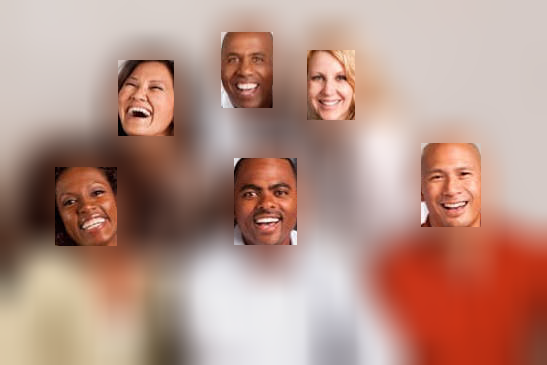

In [33]:
# ejercicio 2
img = Image.open(file)
original = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)
borrosa = cv2.GaussianBlur(original, (51, 51), 30)

alto, ancho, _ = original.shape

for cara in response['FaceDetails']:
    caja = cara['BoundingBox']
    x = int(ancho * caja['Left'])
    y = int(alto * caja['Top'])
    w = int(ancho * caja['Width'])
    h = int(alto * caja['Height'])

    # evitar salirse de la imagen
    x = max(x, 0)
    y = max(y, 0)

    borrosa[y:y+h, x:x+w] = original[y:y+h, x:x+w]

cv2.imwrite('fondo_borroso.jpg', borrosa)
cv2_imshow(borrosa)

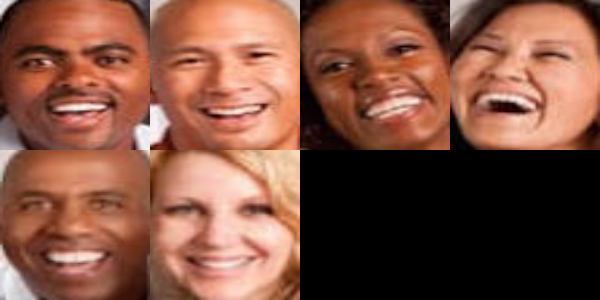

In [34]:
# ejercicio 3
img = Image.open(file)
original = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)
alto, ancho, _ = original.shape

tam = 150          # tamaño de cada cara (cuadrada)
filas = 2
columnas = 4

recortes = []
for cara in response['FaceDetails']:
    caja = cara['BoundingBox']
    x = max(int(ancho * caja['Left']), 0)
    y = max(int(alto * caja['Top']), 0)
    w = int(ancho * caja['Width'])
    h = int(alto * caja['Height'])

    recorte = original[y:y+h, x:x+w]
    recorte = cv2.resize(recorte, (tam, tam))
    recortes.append(recorte)

# lienzo negro para el collage
collage = np.zeros((filas * tam, columnas * tam, 3), dtype=np.uint8)

for i, recorte in enumerate(recortes):
    if i >= filas * columnas:
        break  # no caben más caras
    fila = i // columnas
    col = i % columnas
    collage[fila*tam:(fila+1)*tam, col*tam:(col+1)*tam] = recorte

cv2.imwrite('collage.jpg', collage)
cv2_imshow(collage)